In [1]:
import os
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..')
pth_in = os.path.join(pth, 'data', 'cancer', 'marenaria')
pth_out = os.path.join(pth, 'figures', 'marenaria')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'MarBTN.h5ad'))
adata.obs['sample'] = adata.obs_names.astype('category')
adata

AnnData object with n_obs × n_vars = 6 × 43038
    obs: 'sample'
    uns: 'log1p'
    layers: 'counts'

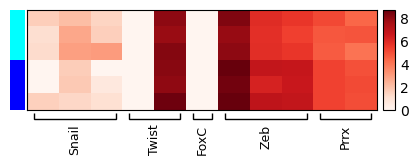

In [5]:
g_plt = {
    'Snail' : ['LOC128242410', 'LOC128243129', 'LOC128243408'],
    'Twist' : ['LOC128243558', 'LOC128244610'],
    'FoxC'  : ['LOC128244946'],
    'Zeb'   : ['LOC128234774', 'LOC128243217', 'LOC128220362'],
    'Prrx'  : ['LOC128227203', 'LOC128226215']}
adata.uns['sample_colors'] = ['blue'] * 3 + ['cyan'] * 3

# expression heatmap
hm = sc.pl.heatmap(adata, g_plt, 'sample',
                   cmap = 'Reds',
                   figsize = (5, 1.5),
                   show_gene_labels = False,
                   show = False)

ax_hm = hm['heatmap_ax']
ax_grp = hm['groupby_ax']
ax_var = hm['gene_groups_ax']
ax_cb = ax_hm.figure.axes[1]

pos_hm  = ax_hm.get_position()
pos_var = ax_var.get_position()
pos_cb = ax_cb.get_position()

ax_grp.set_yticks([])
ax_grp.set_ylabel('')

for ax in (ax_hm, ax_grp, ax_var):
    ax.invert_yaxis()

for t in ax_var.texts:
    t.set_va('top')
    t.set_fontsize(9)

for l in ax_var.patches:
    l.set_linewidth(1)

for l in ax_hm.collections:
    l.remove()

ax_var.set_position([pos_var.x0,
                     pos_hm.y0 - pos_var.height - .02,
                     pos_var.width,
                     pos_var.height])

ax_cb.set_position([pos_cb.x0, pos_cb.y0,
                    .025, pos_cb.height])
ax_cb.set_yticks([0, 2, 4, 6, 8])
ax_cb.tick_params(length = 0)

fn = os.path.join(pth_out, 'expression.pdf')
plt.savefig(fn, bbox_inches = 'tight', dpi = 1200)